# imports

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from astropy.io import fits
import astropy.units as u
import astropy.constants as c

from matplotlib.patches import Circle
from astrodendro import Dendrogram

In [2]:
def first_moment(array,sum_axis):
    num = np.nansum(array*sum_axis[:,np.newaxis,np.newaxis],axis=0)
    den = np.nansum(array,axis=0)
    
    return num/den


def second_moment(array,sum_axis):
    m1 = first_moment(array,sum_axis)
    
    
    num = np.nansum(array*(sum_axis[:,np.newaxis,np.newaxis]-m1[np.newaxis,:])**2,axis=0)
    den = np.nansum(array,axis=0)
    
    return np.sqrt(num/den)


def R_HI(MH2,nHI=0.57):
    num = MH2*u.Msun
    den = 2*np.pi*nHI*u.cm**-3*c.m_p

    return (num/den)**(1/3)

# molecular cloud catalogs

In [ ]:
ibb_tab1 = pd.read_csv('ibb_tab1.csv')
g12_tab1 = pd.read_csv('gratier_tab1.txt',sep=r'\s+')
c17_tab5 = pd.read_csv('corbelli_tab5.txt',sep=r'\s+')

#find or ask eric about alma catalog

In [4]:
m33_120pc = fits.open('../data/m33_C+D+tp_himidres_120pc.fits')[0].data[60:180] # just choosing velocities between -53 and -300 km/s

header = fits.open('../data/m33_C+D+tp_himidres_120pc.fits')[0].header

rax,dax,vax = [(np.arange(header[f'NAXIS{n}'])-header[f'CRPIX{n}'])*header[f'CDELT{n}'] + header[f'CRVAL{n}'] for n in [1,2,3]]
vax = (vax/1e3)[60:180]

In [5]:
m0 = np.nansum(m33_120pc*2.061,axis=0)#*u.K*u.km/u.s
m0_lv = np.nansum(m33_120pc,axis=1)
m0_bv = np.nansum(m33_120pc,axis=2)


m1 = first_moment(m33_120pc,vax)
m2 = second_moment(m33_120pc,vax)

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_75709/1708027137.py:5: RuntimeWarning: invalid value encountered in divide
  return num/den
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_75709/1708027137.py:15: RuntimeWarning: invalid value encountered in divide
  return np.sqrt(num/den)
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_75709/1708027137.py:15: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(num/den)


In [8]:
rax[[0,-1]]

array([24.12218056, 22.81065278])

In [45]:
vax[[0,-1]]

array([ -53.41890481, -298.76861834])

In [9]:
dax[[0,-1]]

array([29.86883333, 31.44286111])

In [18]:
m33_120pc.shape

(120, 1620, 1350)

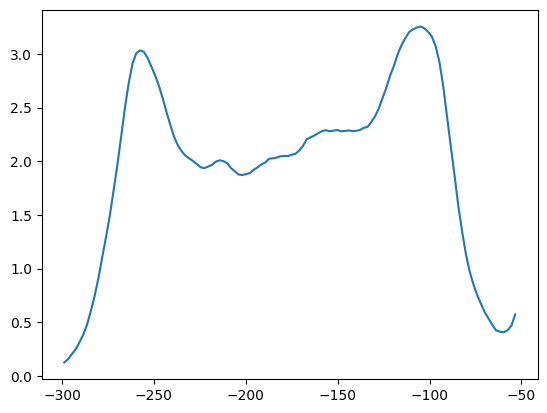

In [99]:
plt.plot(vax,np.nanmean(m33_120pc,axis=(1,2)))

In [61]:
help(plt.colorbar)

Help on function colorbar in module matplotlib.pyplot:

colorbar(mappable: 'ScalarMappable | ColorizingArtist | None' = None, cax: 'matplotlib.axes.Axes | None' = None, ax: 'matplotlib.axes.Axes | Iterable[matplotlib.axes.Axes] | None' = None, **kwargs) -> 'Colorbar'
    Add a colorbar to a plot.
    
    Parameters
    ----------
    mappable
        The `matplotlib.cm.ScalarMappable` (i.e., `.AxesImage`,
        `.ContourSet`, etc.) described by this colorbar.  This argument is
        mandatory for the `.Figure.colorbar` method but optional for the
        `.pyplot.colorbar` function, which sets the default to the current
        image.
    
        Note that one can create a `.ScalarMappable` "on-the-fly" to
        generate colorbars not attached to a previously drawn artist, e.g.
        ::
    
            fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax)
    
    cax : `~matplotlib.axes.Axes`, optional
        Axes into which the colorbar will be drawn.  If `None`, t

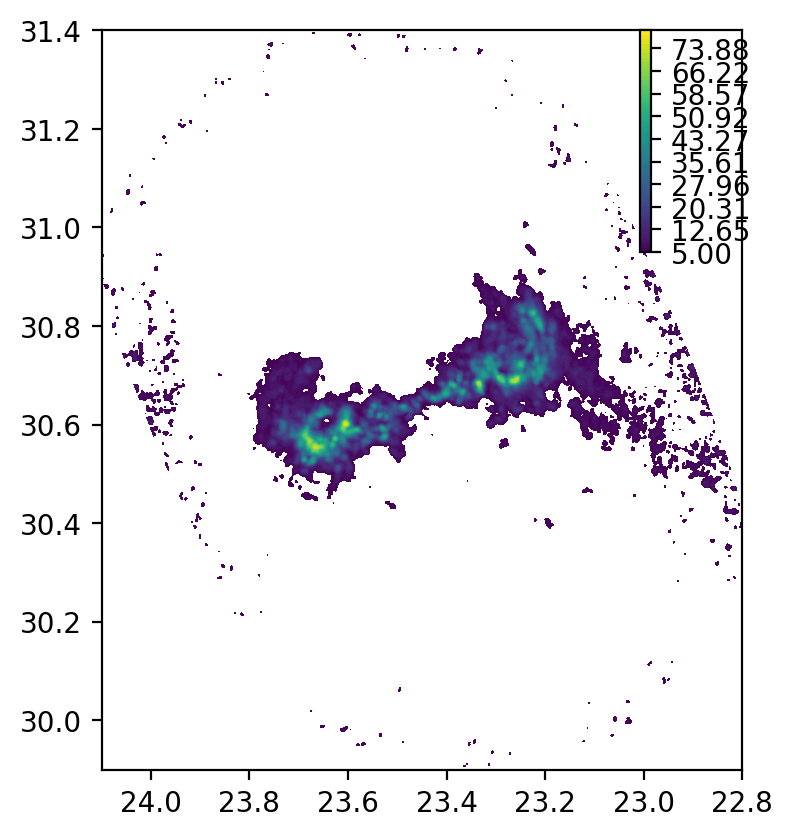

In [100]:
plt.figure(dpi=200)
plt.contourf(m33_120pc[60],levels=np.linspace(5,80),extent=[24.1,22.8,29.9,31.4])
plt.gca().set_aspect(1)
plt.xlim(24.1,22.8)
plt.colorbar(shrink=0.3,anchor=(-1.1,1))#,ticks=5)
# plt.ylim(30,31.3)

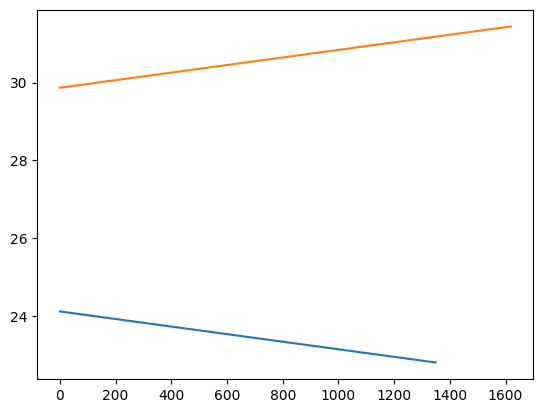

In [102]:
plt.plot(rax)
plt.plot(dax)
# plt.plot(vax)

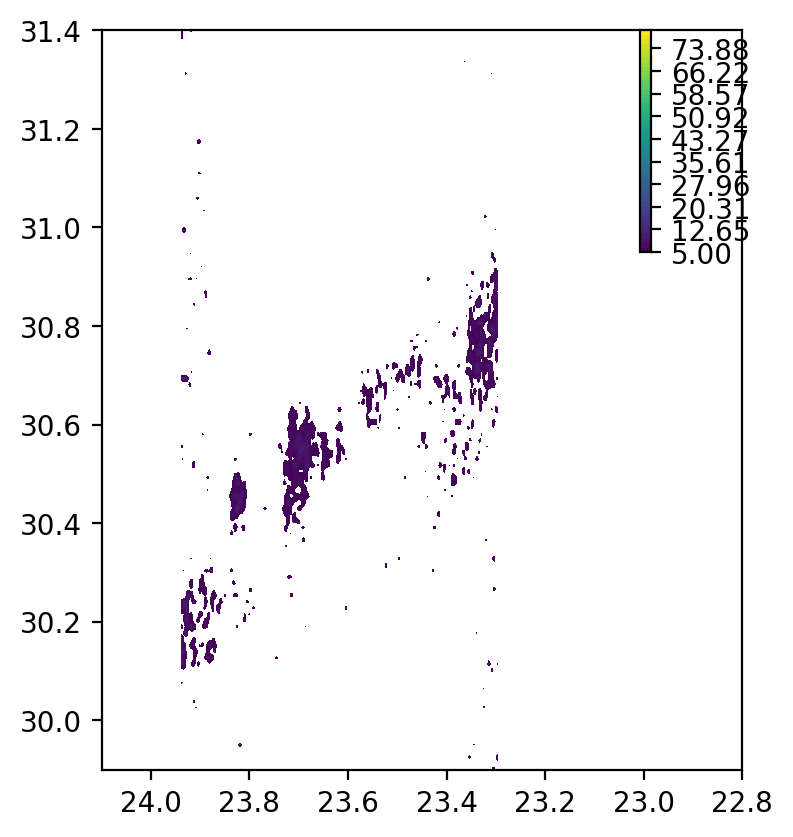

In [104]:
plt.figure(dpi=200)
plt.contourf(m33_120pc[:,:,1200],levels=np.linspace(5,80),extent=[24.1,22.8,29.9,31.4])
plt.gca().set_aspect(1)
plt.xlim(24.1,22.8)
plt.colorbar(shrink=0.3,anchor=(-1.1,1))#,ticks=5)
# plt.ylim(30,31.3)

(24.1, 22.8)

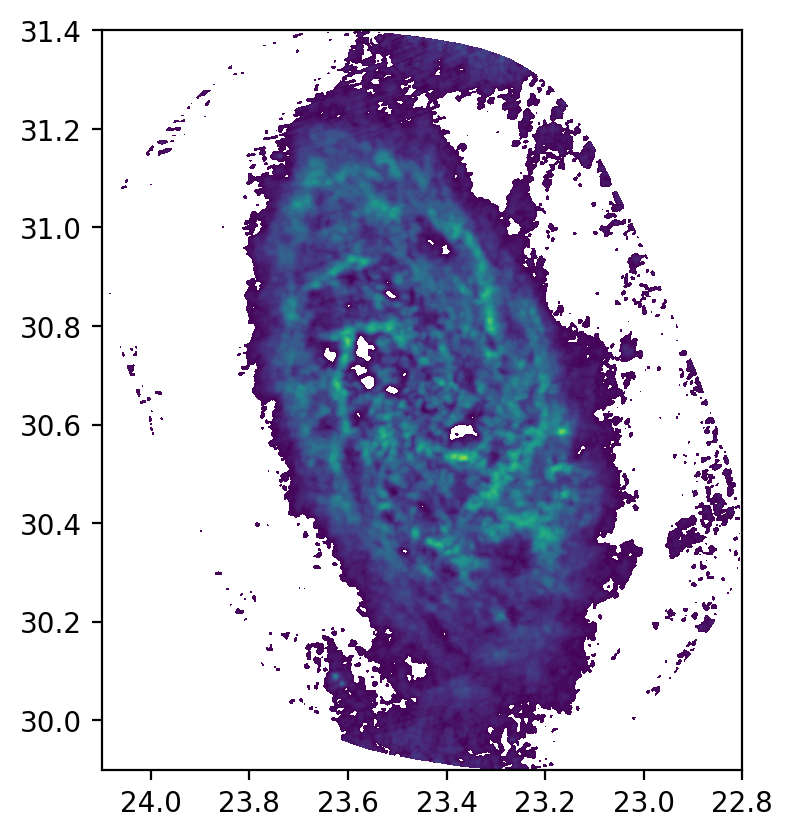

In [54]:
plt.figure(dpi=200)
plt.contourf(m0,levels=np.linspace(300,3000),extent=[24.1,22.8,29.9,31.4])
plt.gca().set_aspect(1)
plt.xlim(24.1,22.8)
# plt.ylim(30,31.3)

(-74.6, -310.0)

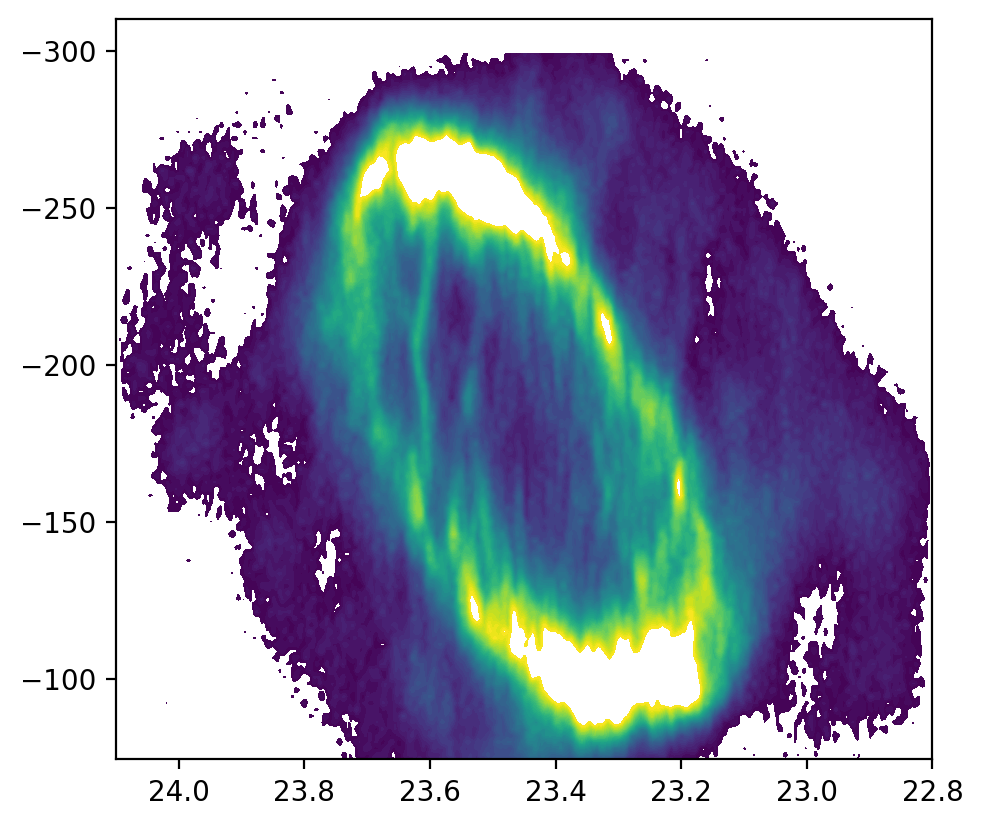

In [105]:
plt.figure(dpi=200)

plt.contourf(m0_lv,levels=np.linspace(500,10000),extent=[24.1,22.8,-53,-299])

plt.gca().set_aspect(5e-3)
plt.xlim(24.1,22.8)
plt.ylim(-74.6,-310)

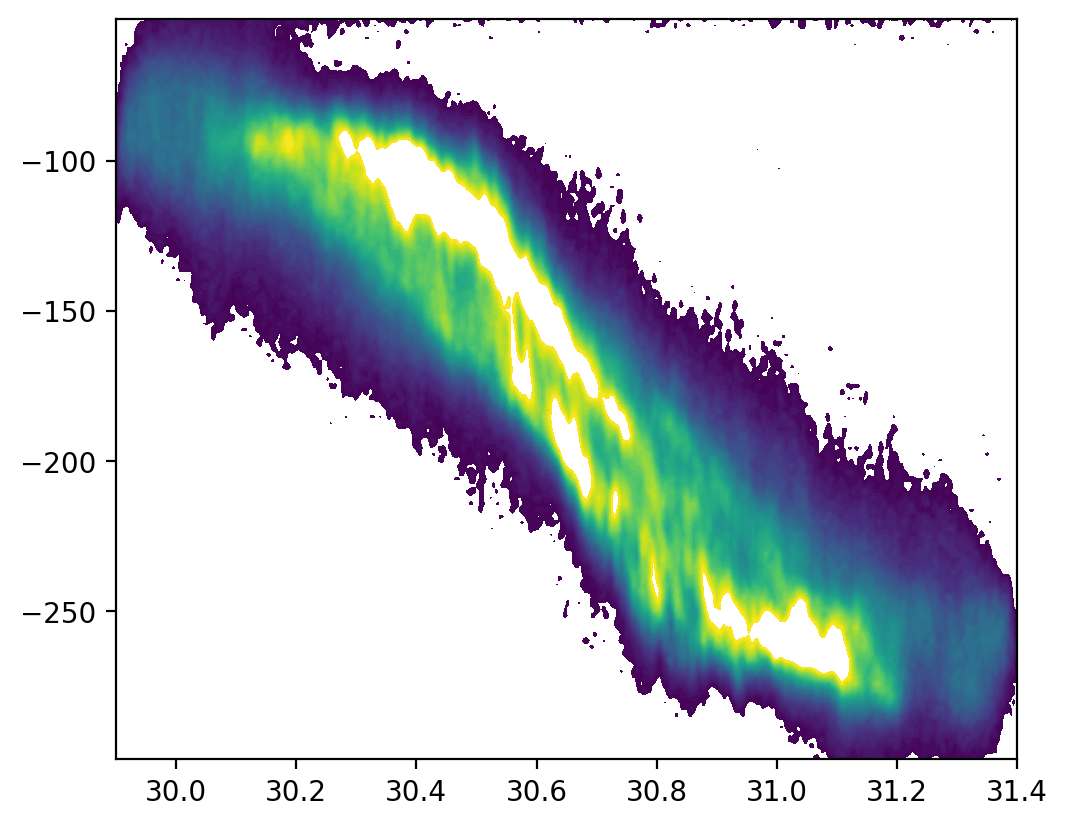

In [43]:
plt.figure(dpi=200)

plt.contourf(m0_bv,levels=np.linspace(500,10000),extent=[29.9,31.4,-53,-299])

plt.gca().set_aspect(5e-3)
# plt.xlim(24.1,22.8)

In [41]:
dax[[0,-1]]

array([29.86883333, 31.44286111])

In [13]:
rHI_pc = R_HI(ibb_tab1['M_GMC_1e4_Msun'].to_numpy()*1e4).to(u.pc).value
rHI_an = (rHI_pc/859000)*u.rad.to(u.deg)

In [7]:
header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    3 / number of array dimensions                     
NAXIS1  =                 1350                                                  
NAXIS2  =                 1620                                                  
NAXIS3  =                  241                                                  
BTYPE   = 'Intensity'                                                           
OBJECT  = 'M33_1   '                                                            
BUNIT   = 'K       '           / Brightness (pixel) unit                        
ALTRVAL =   1.420072734544E+09 /Alternate frequency reference value             
ALTRPIX =   1.000000000000E+00 /Alternate frequency reference pixel             
VELREF  =                  257 /1 LSR, 2 HEL, 3 OBS, +256 Radio                 
COMMENT casacore non-standar

In [16]:
plt.rcParams['font.size'] = 20

In [17]:
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['mathtext.fontset'] = 'stix' 

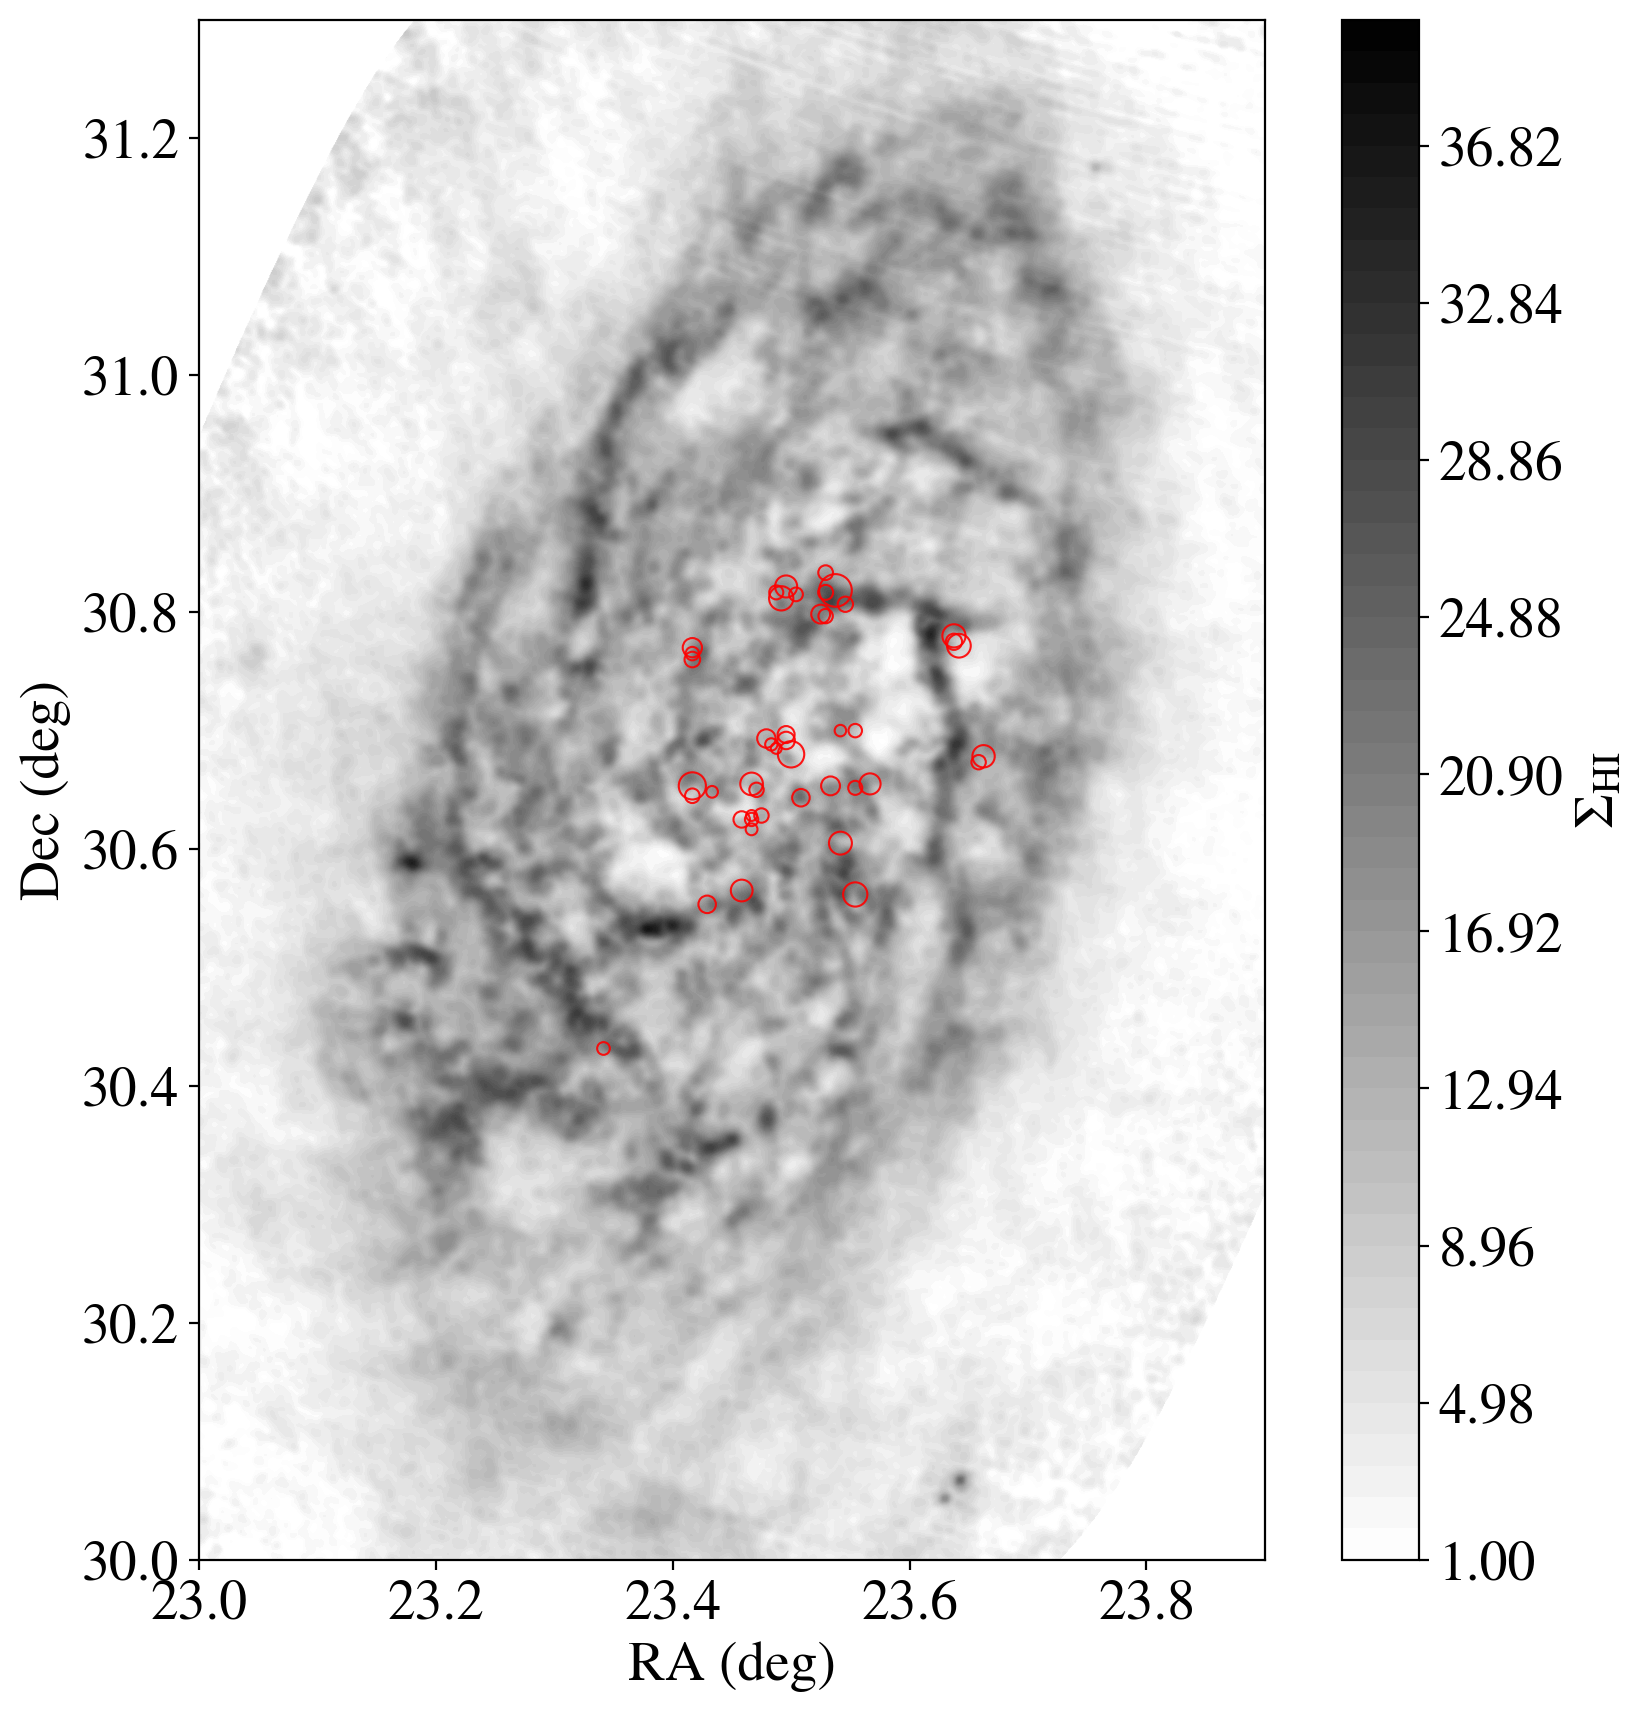

In [20]:
plt.figure(dpi=200,figsize=(10,10))
plt.contourf(m0*0.0146,extent=[rax[0],rax[-1],dax[0],dax[-1]],levels=np.linspace(1,40),cmap='binary')
plt.colorbar(label='$\Sigma_\mathrm{HI}$')

# plt.contour(m0,extent=[rax[0],rax[-1],dax[0],dax[-1]],levels=[250,500],colors='black')

plt.gca().set_aspect(1)

# plt.scatter(c17_tab5['RAdeg'],c17_tab5['DEdeg'],color='orange',marker='*',s=50,alpha=0.7)
ax = plt.gca()
for ra, dec, radius in zip(ibb_tab1['RA_deg'],ibb_tab1['Dec_deg'], rHI_an):
    ax.add_patch(Circle((ra, dec), radius, fill=False,edgecolor='red',alpha=0.9,linewidth=0.75))


plt.ylabel('Dec (deg)')
plt.xlabel('RA (deg)')

plt.xlim(23.,23.9)
plt.ylim(30.,31.3)

plt.show()


# plt.yticks(np.linspace(dax[0],dax[-1],5),)
        #    dec_to_dms(np.linspace(dax[0],dax[-1],5)))
# plt.scatter(23.5+g12_tab1['oRA']*u.arcsec.to(u.deg),
#             30.66+g12_tab1['oDE']*u.arcsec.to(u.deg),color='red',marker='*')






(-300.0, -50.0)

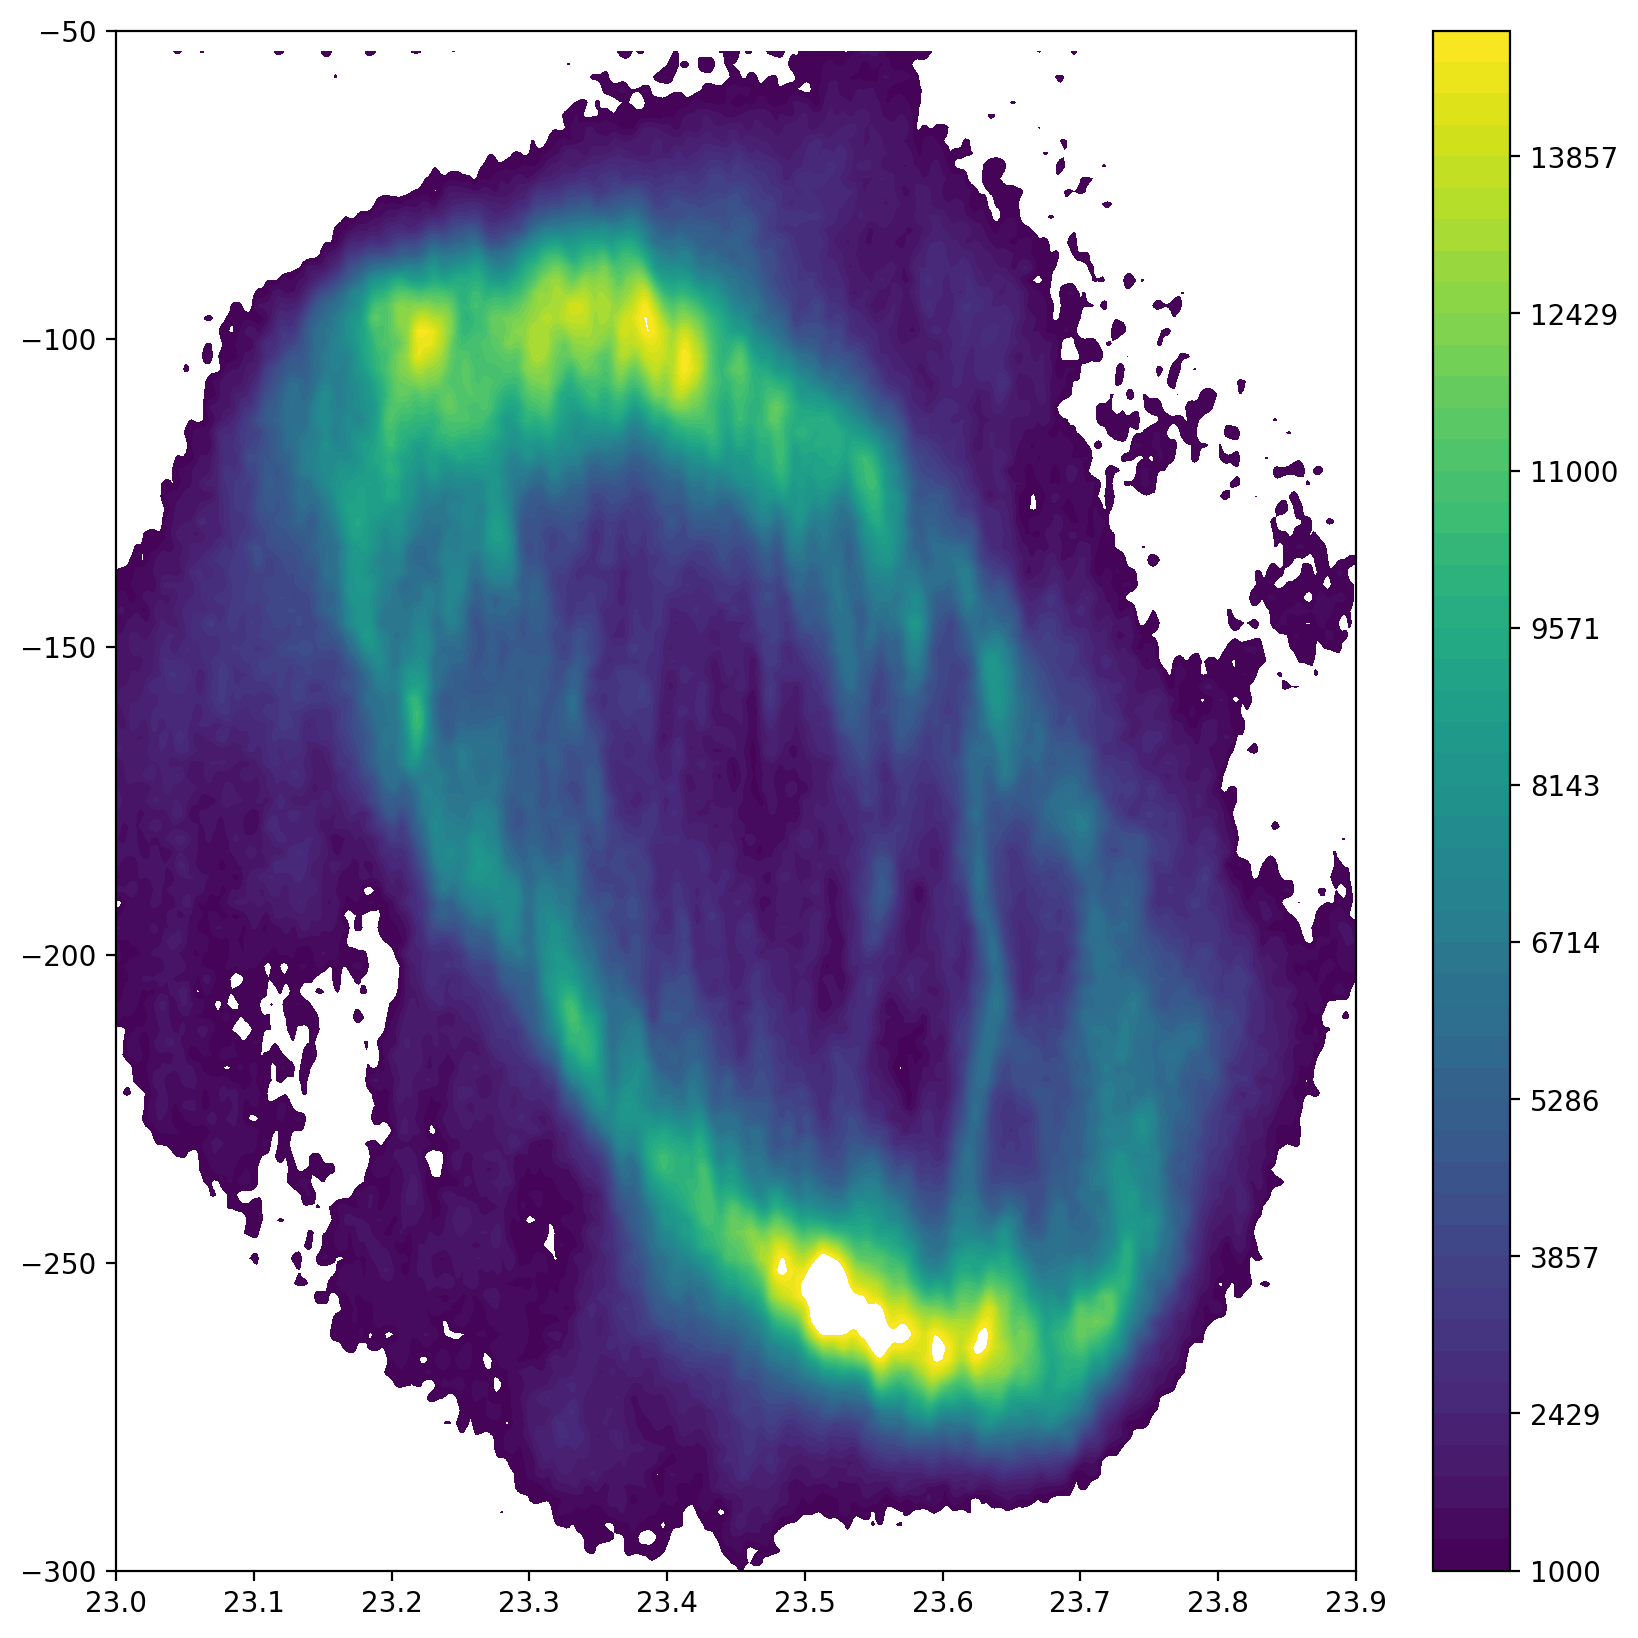

In [ ]:
plt.figure(dpi=200,figsize=(10,10))
plt.contourf(m0_lv,extent=[rax[0],rax[-1],vax[0],vax[-1]],levels=np.linspace(1000,15000))
plt.colorbar()
# plt.gca().set_aspect(1)

plt.xlim(23.,23.9)
plt.ylim(-300.,-50)

(-300.0, -50.0)

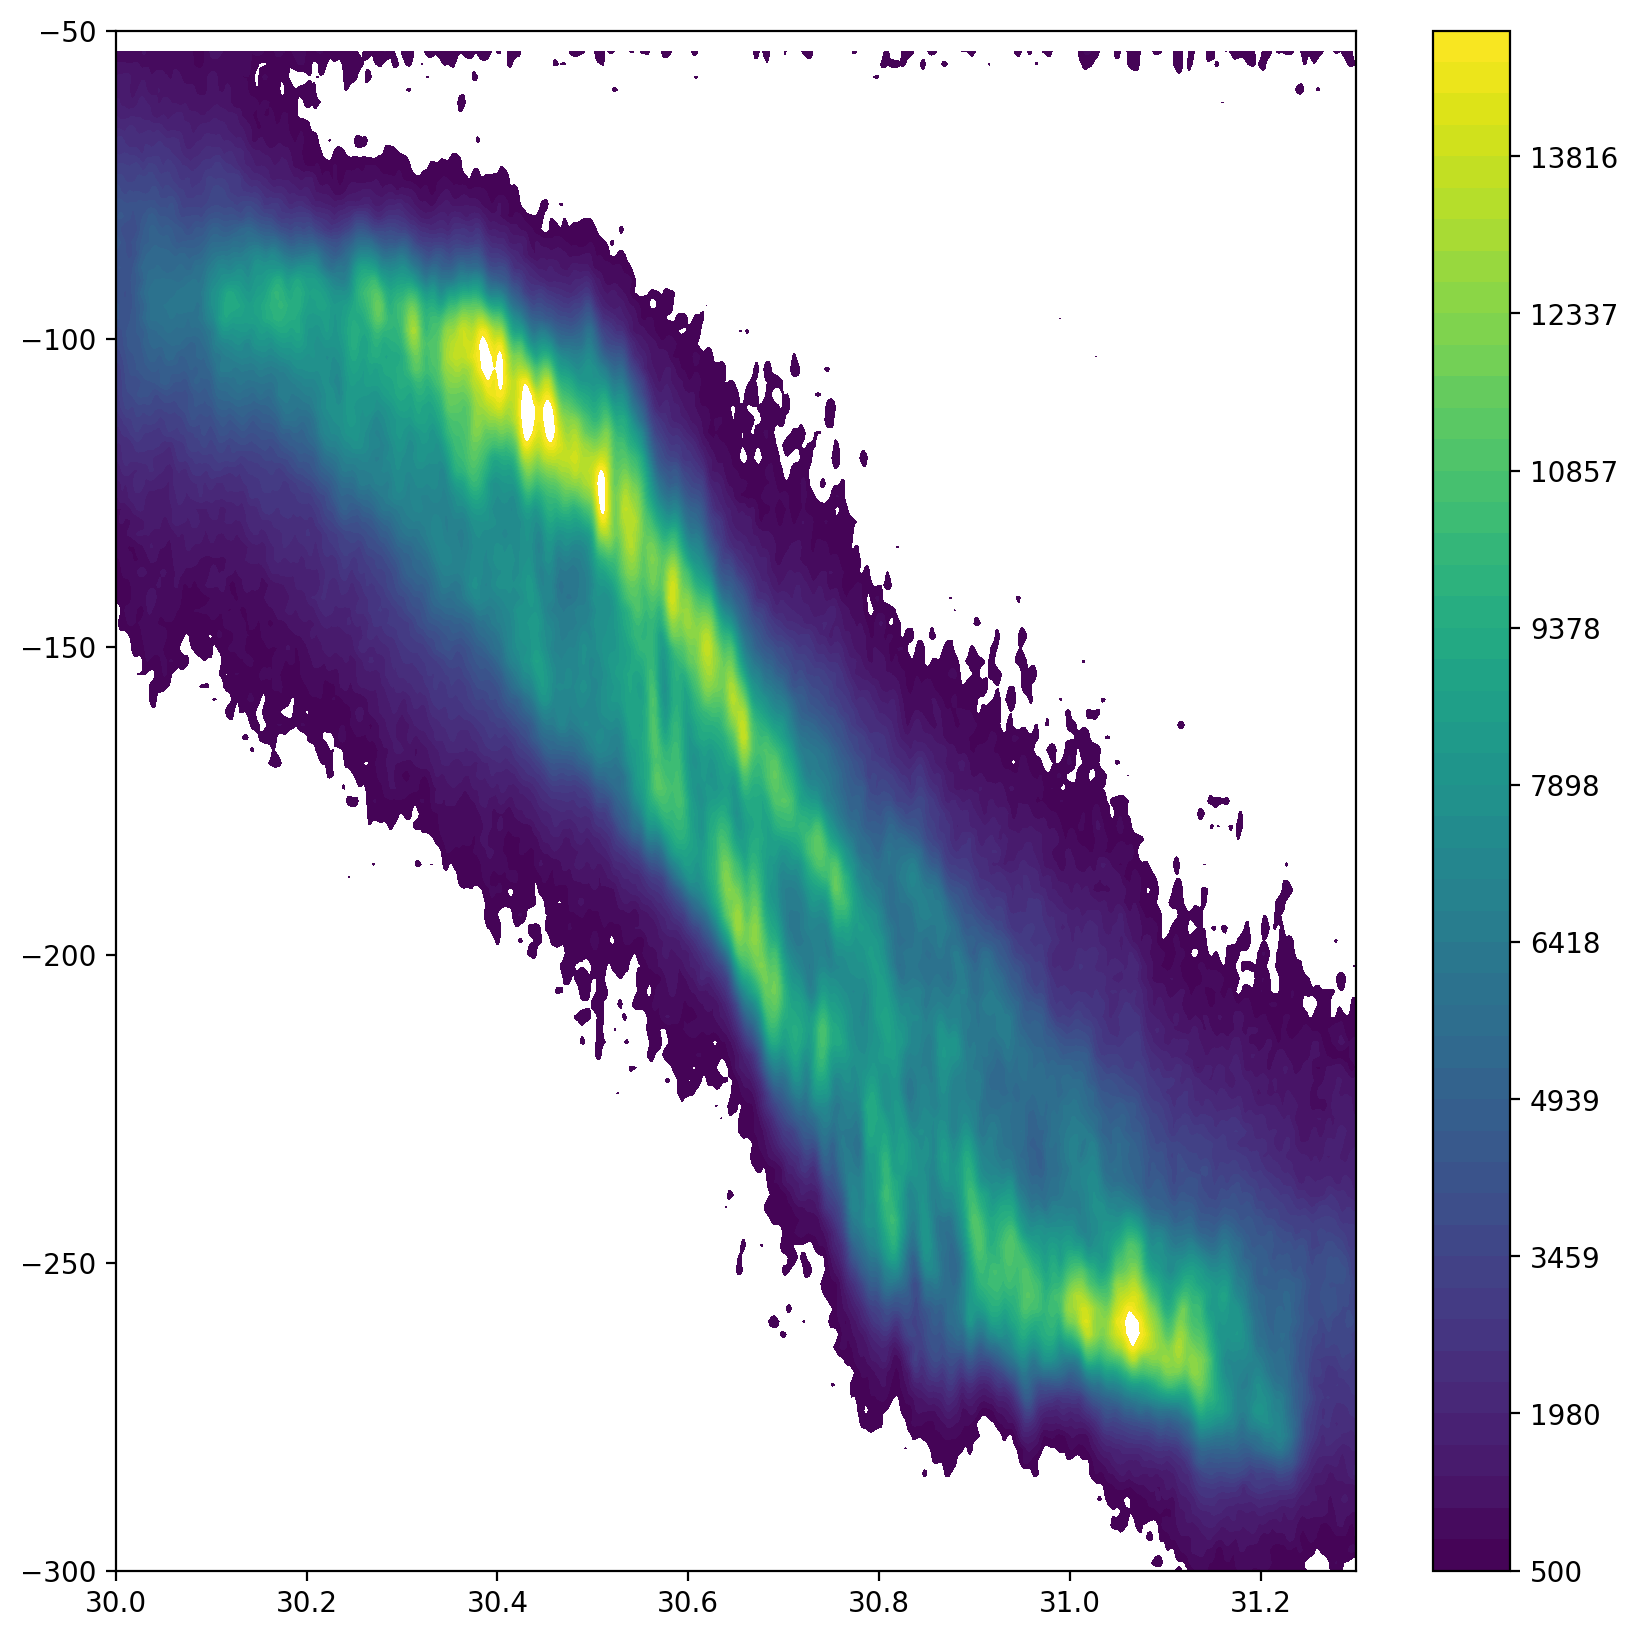

In [ ]:
plt.figure(dpi=200,figsize=(10,10))
plt.contourf(m0_bv,extent=[dax[0],dax[-1],vax[0],vax[-1]],levels=np.linspace(500,15000))
plt.colorbar()
# plt.gca().set_aspect(1)

plt.xlim(30.,31.3)
plt.ylim(-300.,-50)

(30.0, 31.3)

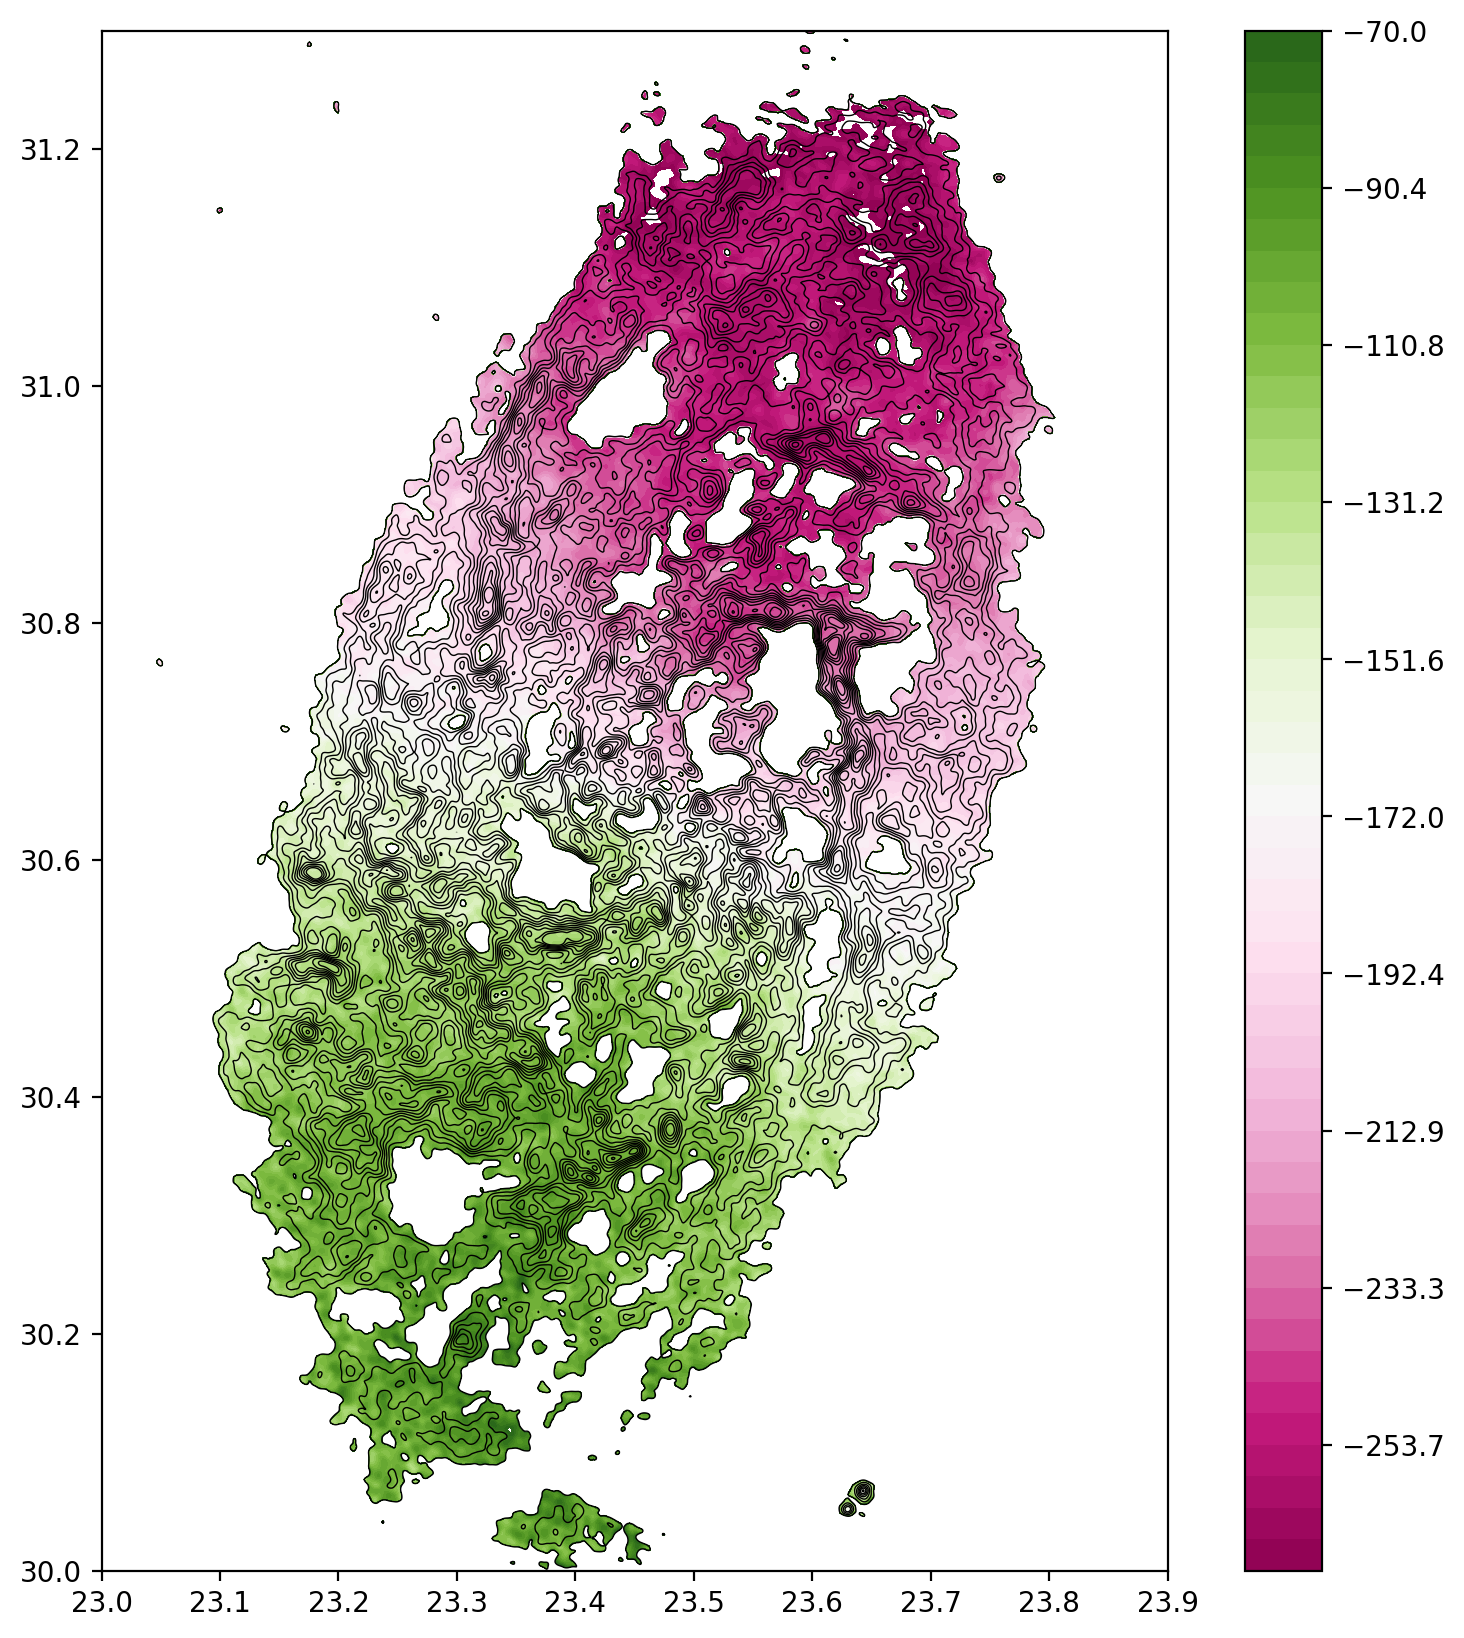

In [ ]:
plt.figure(dpi=200,figsize=(10,10))
plt.contourf(m1*(m0>300),extent=[rax[0],rax[-1],dax[0],dax[-1]],levels=np.linspace(-270,-70),cmap='PiYG')
plt.colorbar()

plt.contour(m0,extent=[rax[0],rax[-1],dax[0],dax[-1]],levels=np.linspace(300,1000,10),colors='black',linewidths=0.5)

plt.gca().set_aspect(1)

plt.xlim(23.,23.9)
plt.ylim(30.,31.3)

(30.0, 31.3)

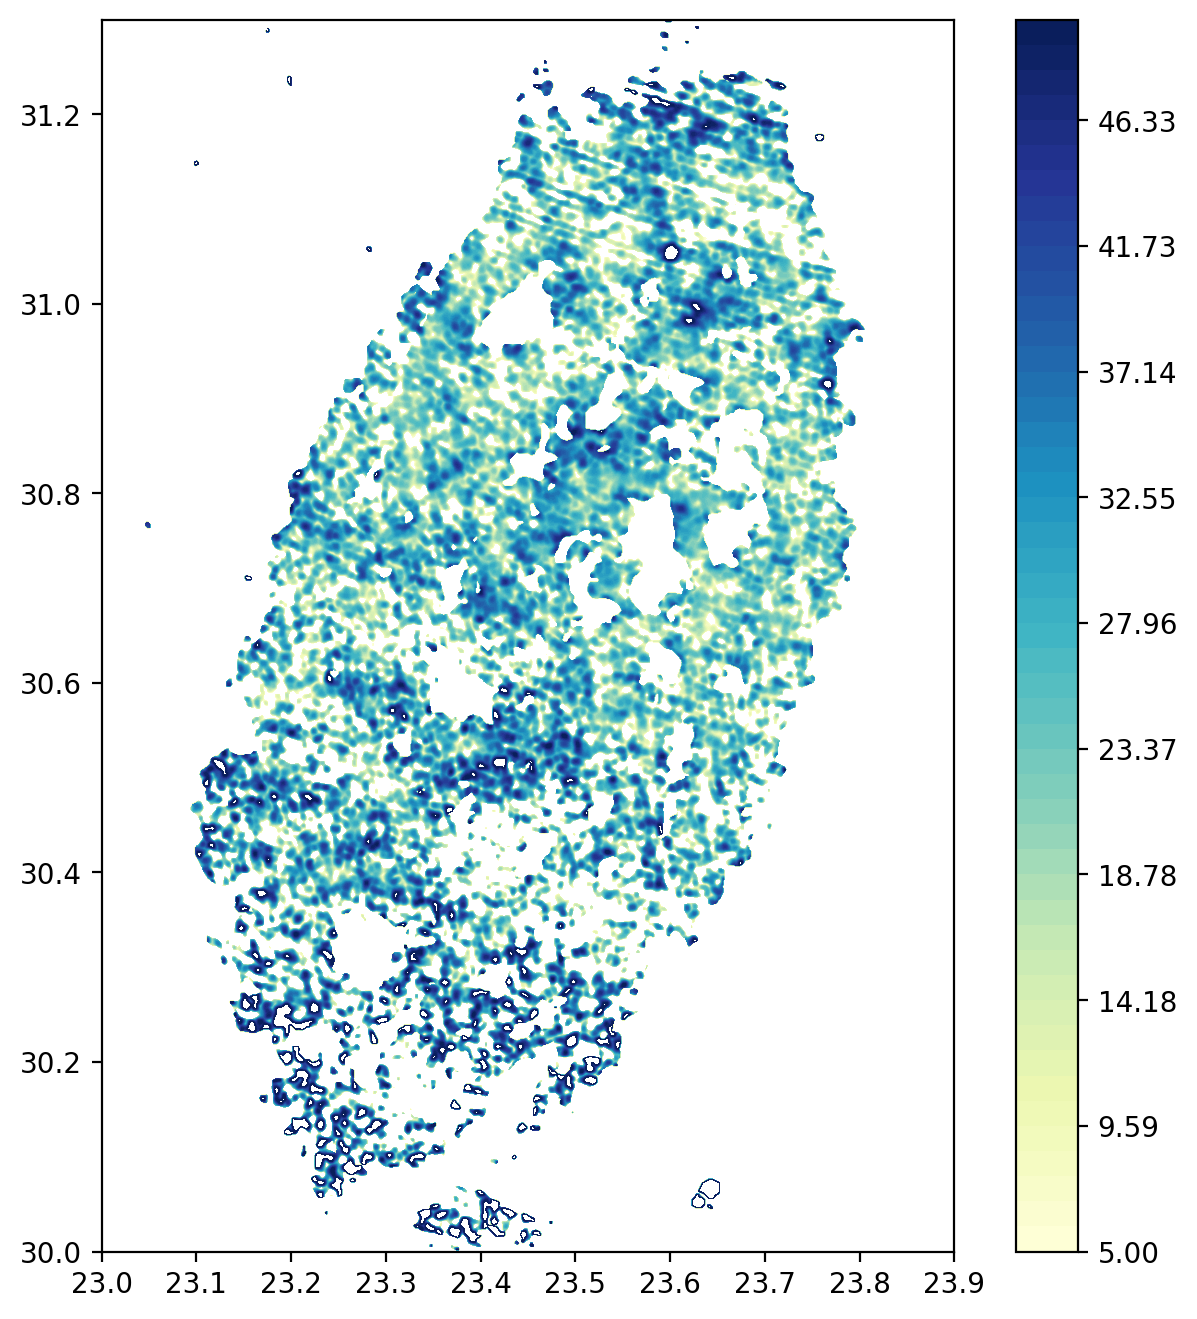

In [ ]:
plt.figure(dpi=200,figsize=(8,8))
plt.contourf(m2*(m0>300),extent=[rax[0],rax[-1],dax[0],dax[-1]],levels=np.linspace(5,50),cmap='YlGnBu')
plt.colorbar()
plt.gca().set_aspect(1)

plt.xlim(23.,23.9)
plt.ylim(30.,31.3)

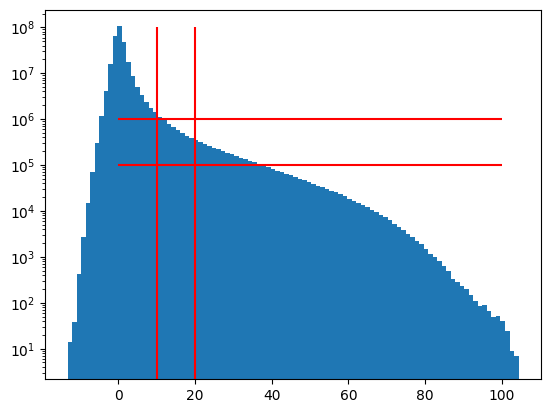

In [ ]:
plt.hist(np.ravel(m33_120pc),bins=100)
plt.yscale('log')

plt.vlines([10,20],0,1e8,color='red')
plt.hlines([1e6,1e5],0,100,color='red')
plt.show()

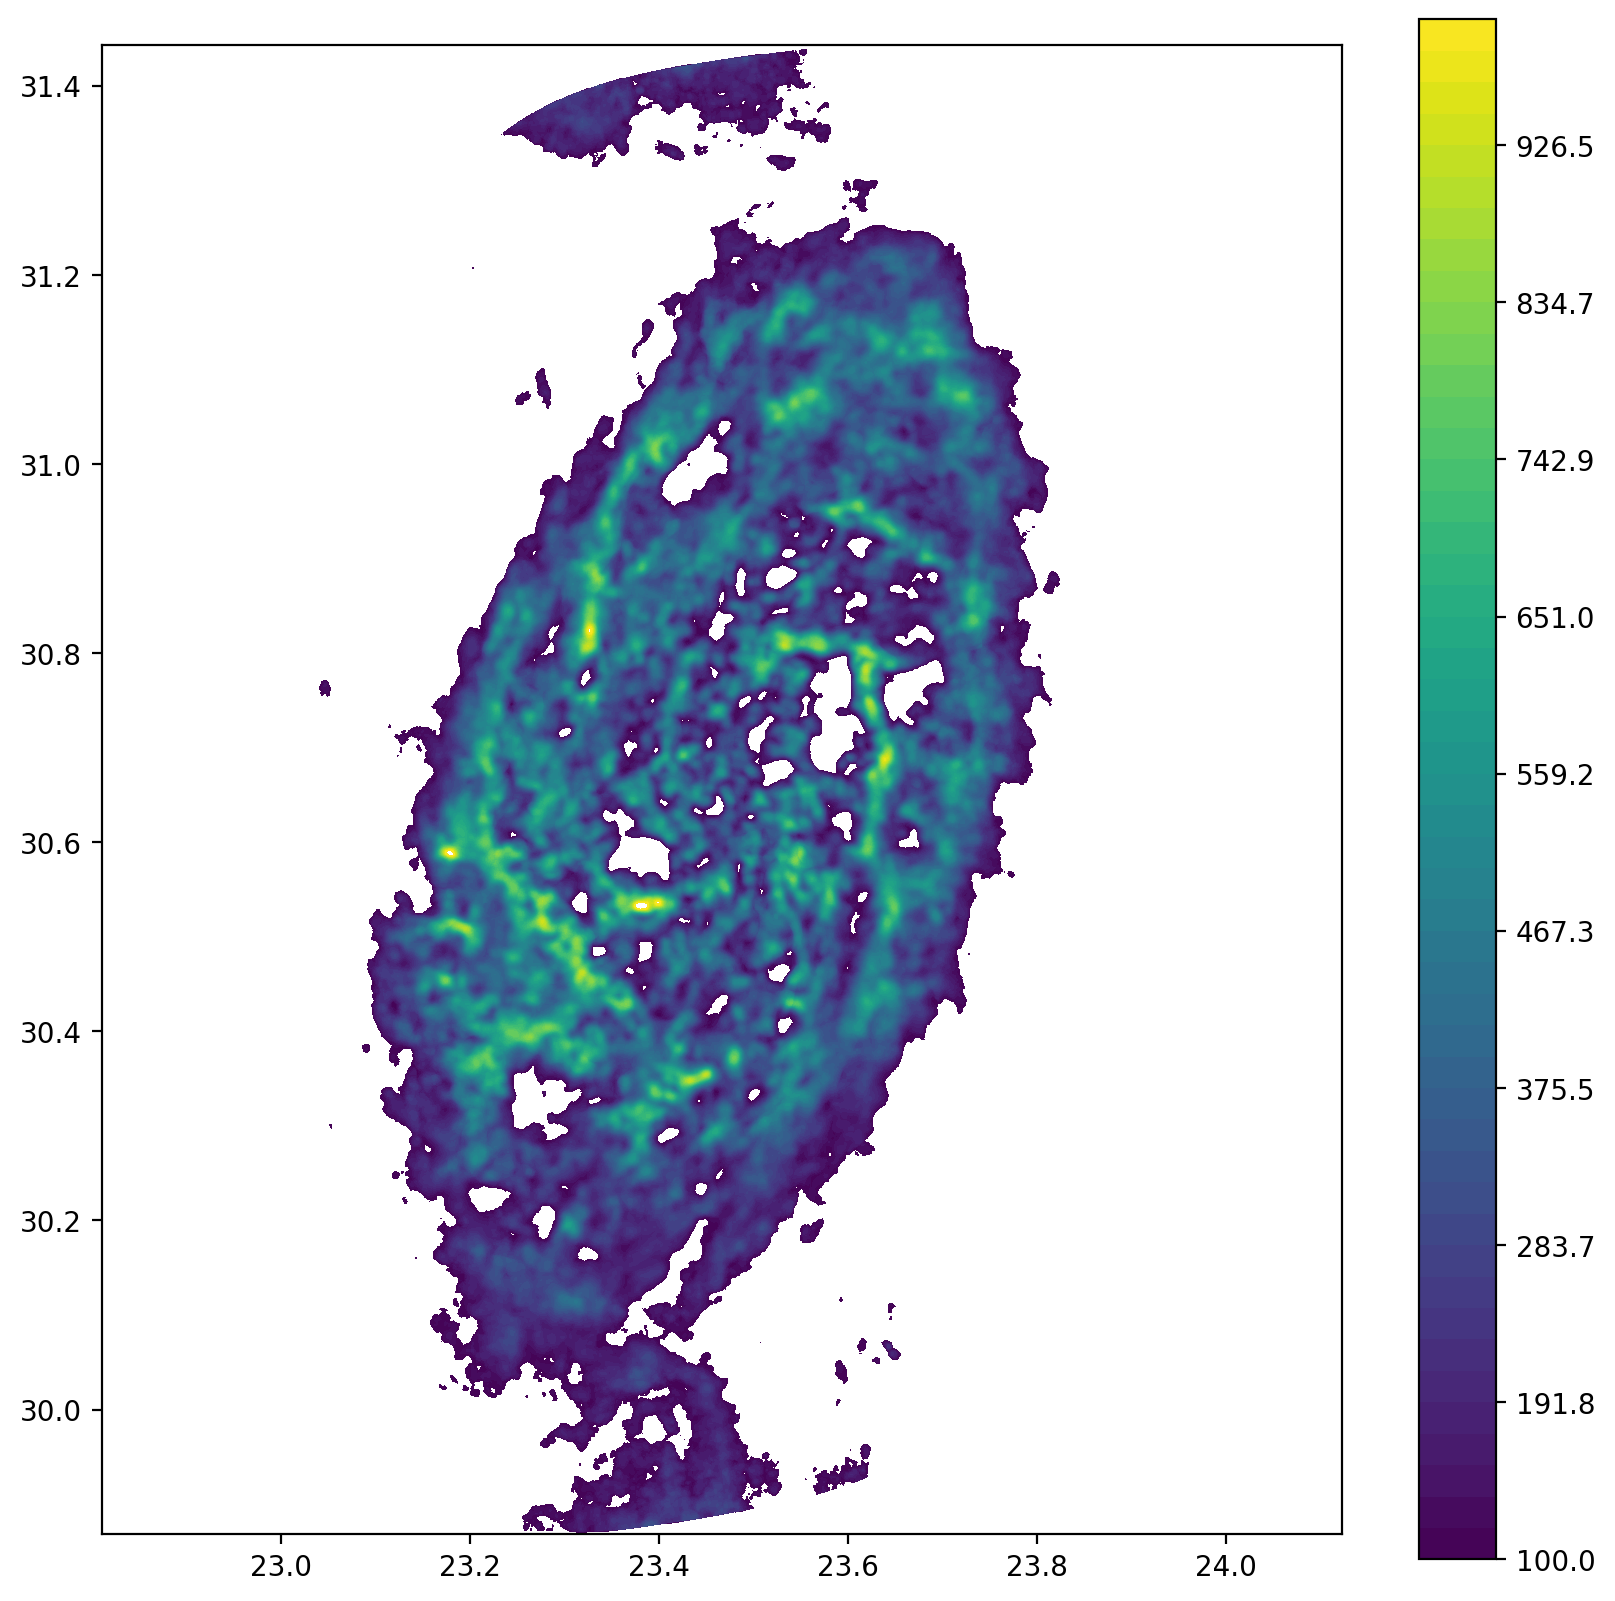

In [ ]:
plt.figure(dpi=200,figsize=(10,10))
plt.contourf(np.nansum(m33_120pc*(m33_120pc>10),axis=0),extent=[rax[0],rax[-1],dax[0],dax[-1]],levels=np.linspace(100,1000))
plt.colorbar()
plt.gca().set_aspect(1)

# plt.xlim(23.,23.9)
# plt.ylim(30.,31.3)

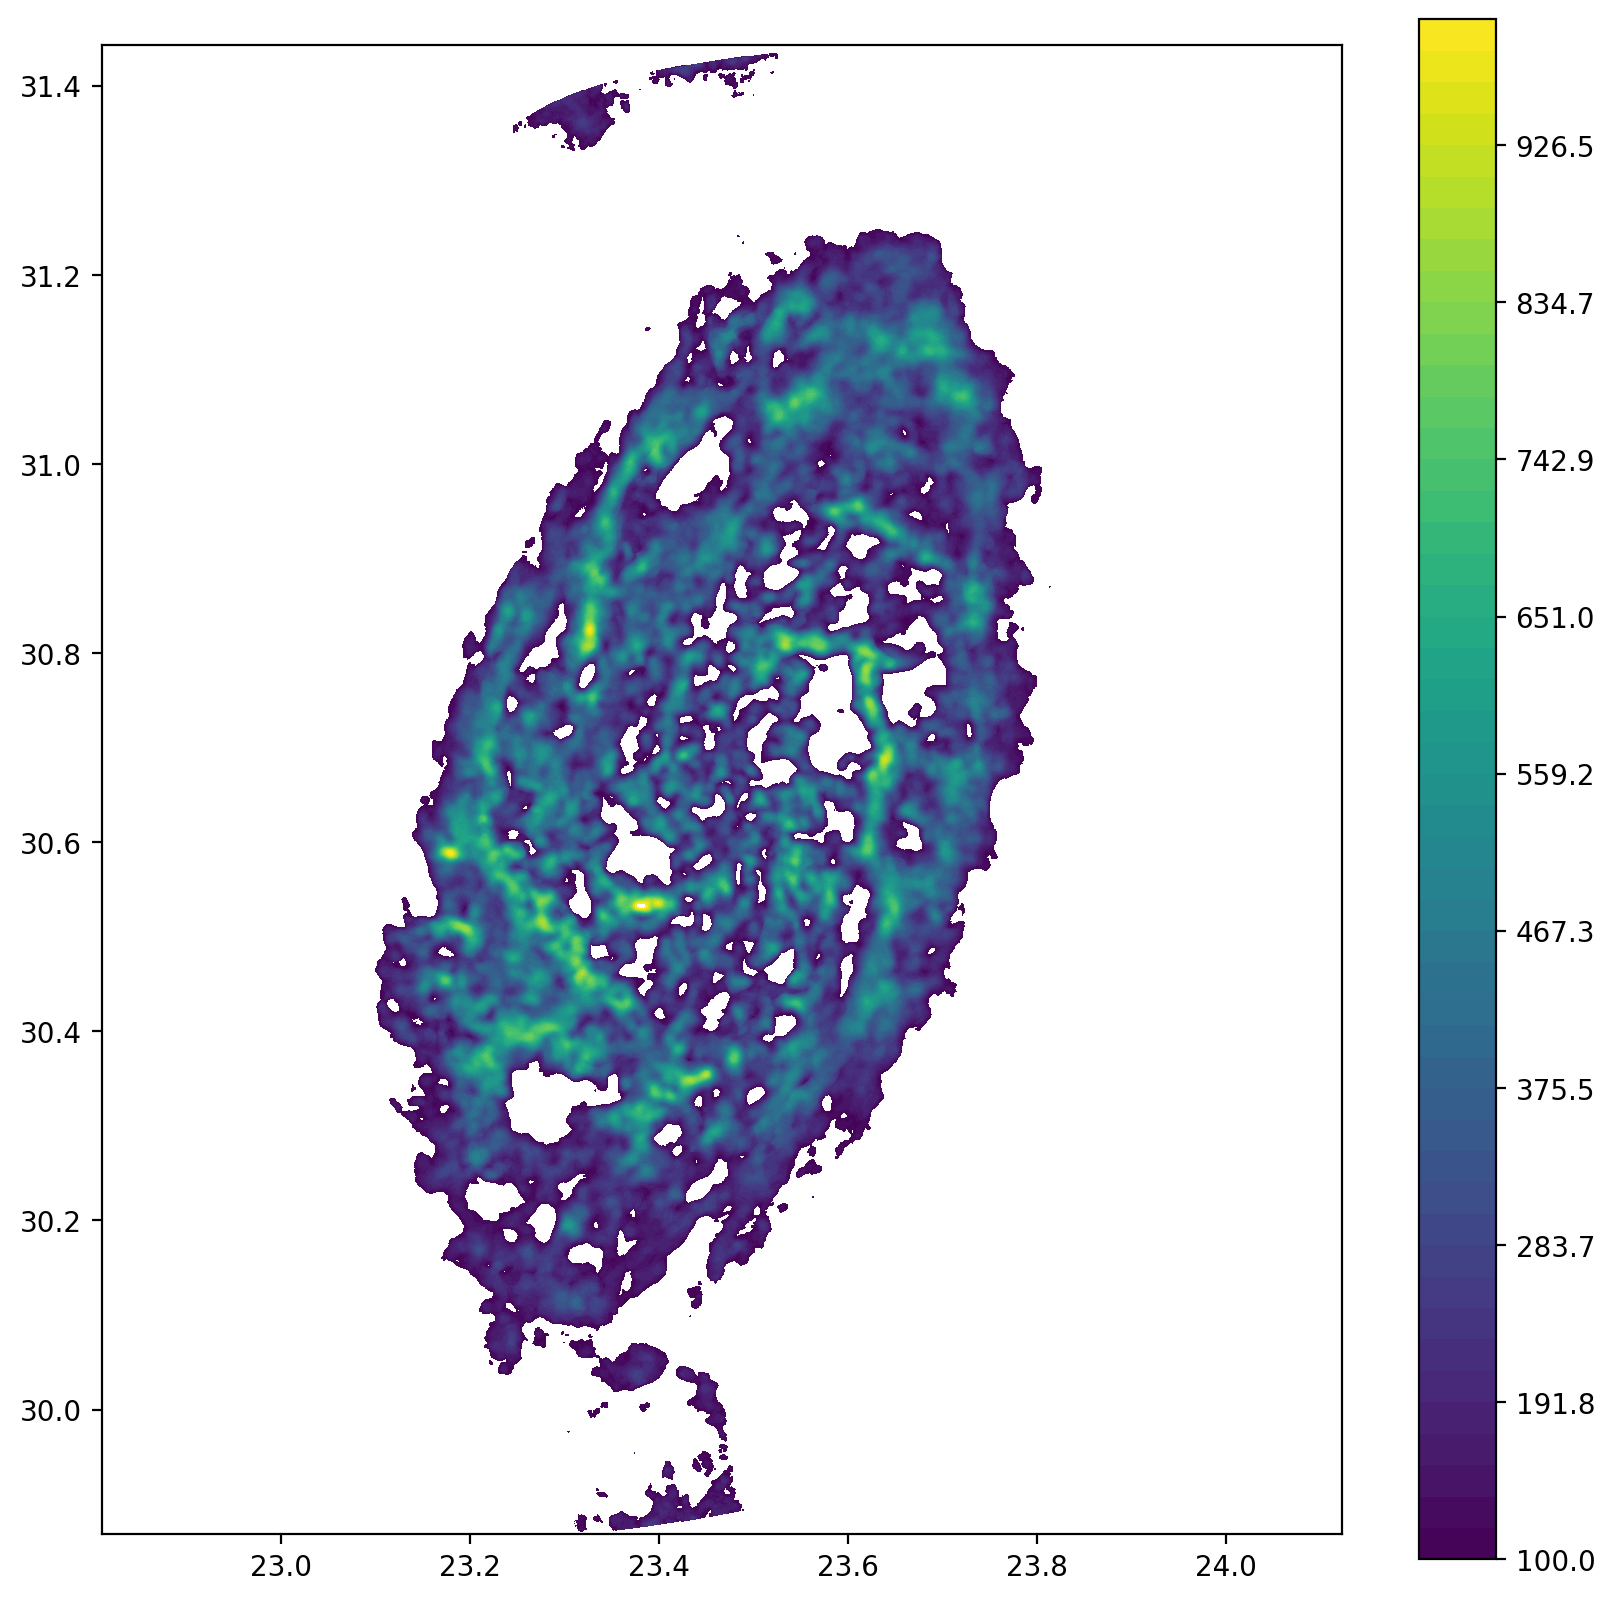

In [ ]:
plt.figure(dpi=200,figsize=(10,10))
plt.contourf(np.nansum(m33_120pc*(m33_120pc>15),axis=0),extent=[rax[0],rax[-1],dax[0],dax[-1]],levels=np.linspace(100,1000))
plt.colorbar()
plt.gca().set_aspect(1)

# plt.xlim(23.,23.9)
# plt.ylim(30.,31.3)

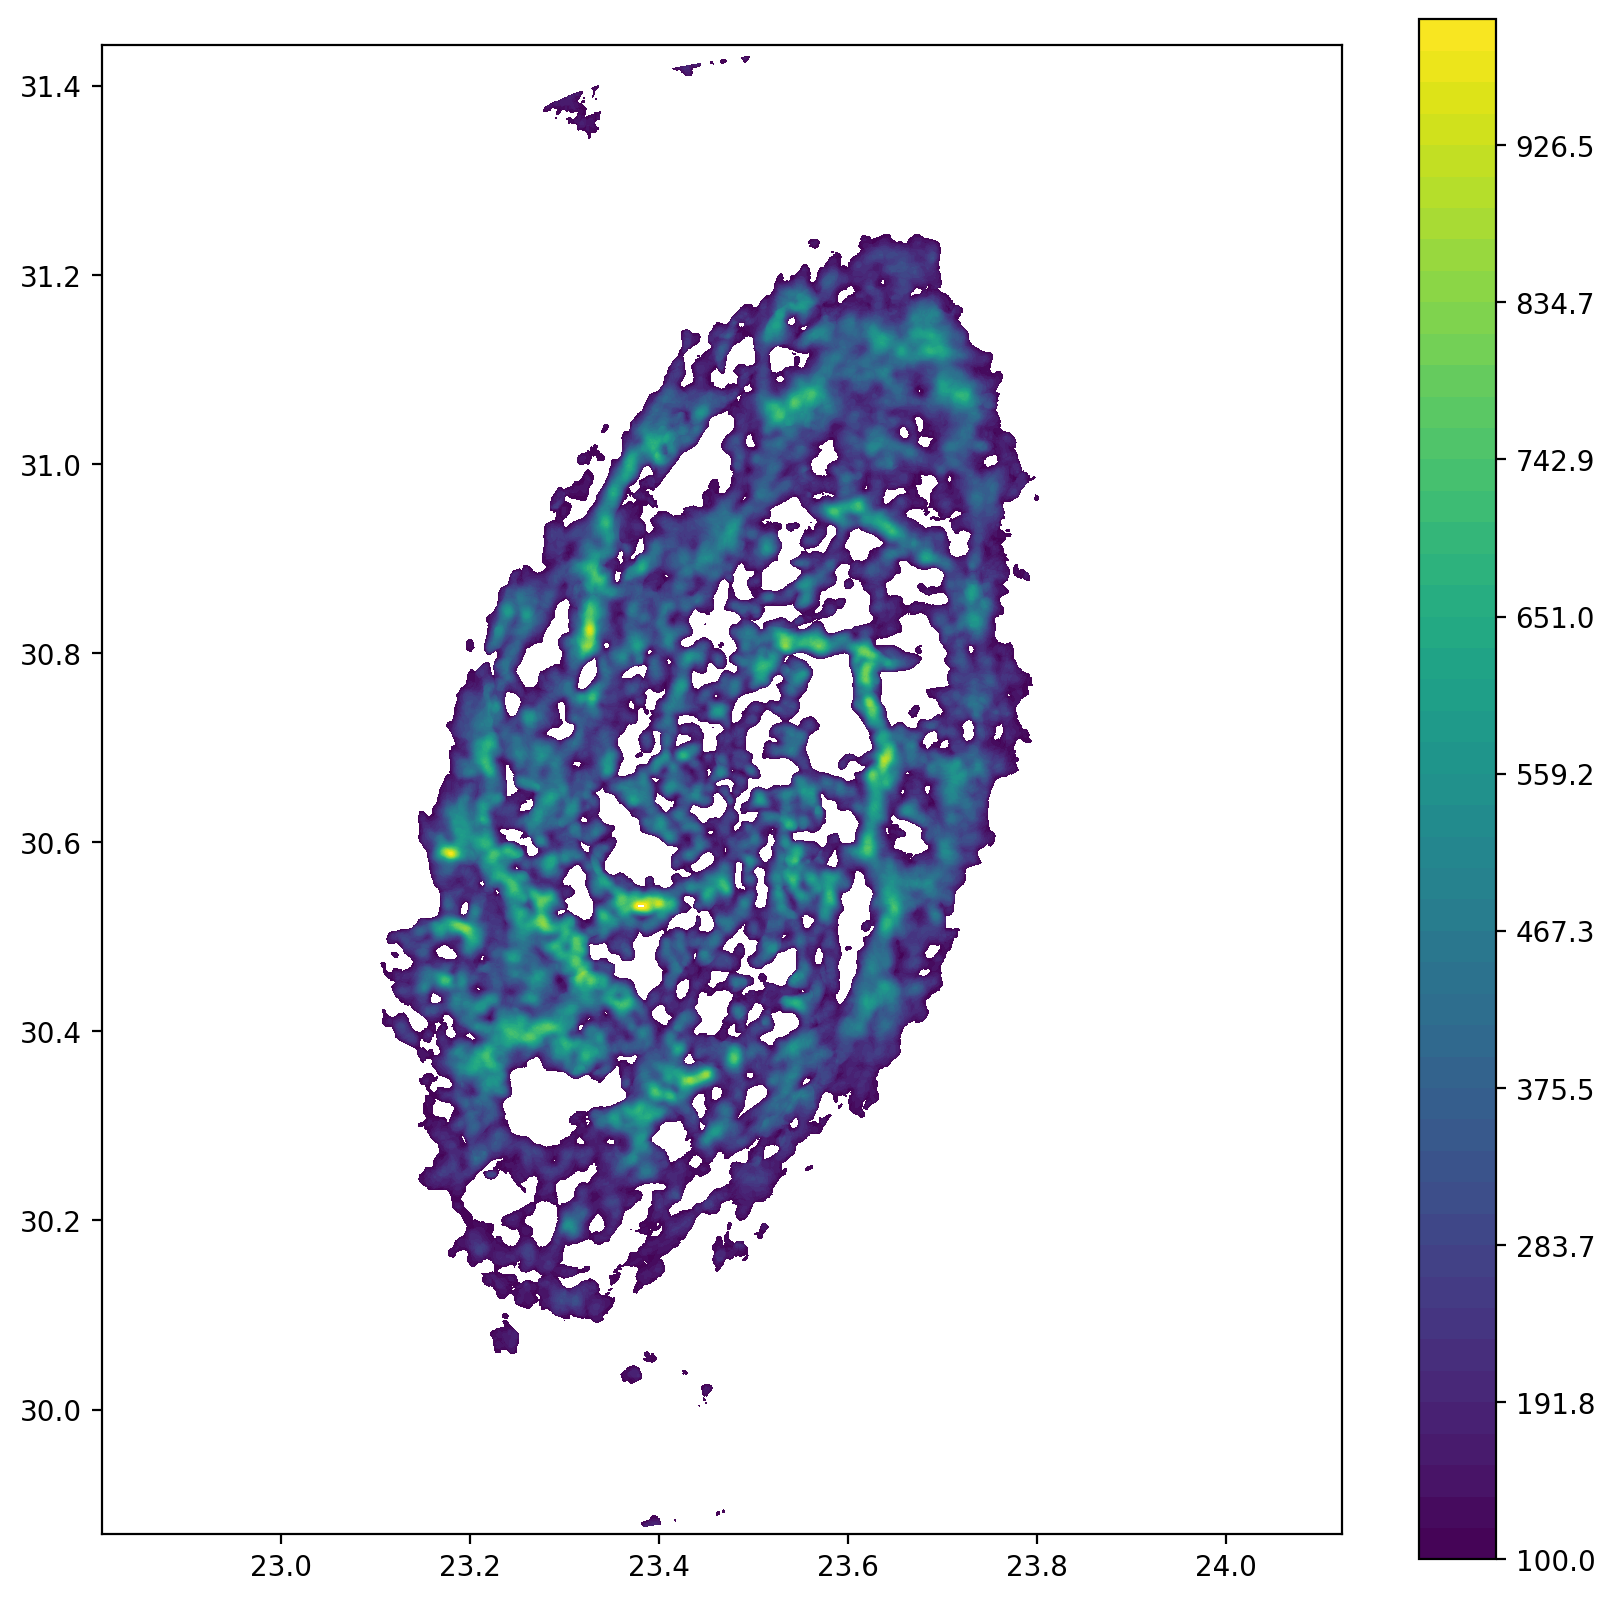

In [ ]:
plt.figure(dpi=200,figsize=(10,10))
plt.contourf(np.nansum(m33_120pc*(m33_120pc>20),axis=0),extent=[rax[0],rax[-1],dax[0],dax[-1]],levels=np.linspace(100,1000))
plt.colorbar()
plt.gca().set_aspect(1)

# plt.xlim(23.,23.9)
# plt.ylim(30.,31.3)